In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

## C1 Setup: data, 5-fold CV and baseline

In [5]:
train = pd.read_csv('C:\\Users\\Rita\\Desktop\\HOUSE-PRICES-ARGISHTI-MARGARIAN\\data\\processed\\train_processed.csv')
test  = pd.read_csv('C:\\Users\\Rita\\Desktop\\HOUSE-PRICES-ARGISHTI-MARGARIAN\\data\\processed\\test_processed.csv')
X, y = train.drop(columns='SalePrice'), train['SalePrice']
test_ids, X_test = test['Id'], test.drop(columns='Id')
assert list(X.columns) == list(X_test.columns)
print('X:', X.shape, ' X_test:', X_test.shape)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def rmse_cv(model):
    return -cross_val_score(model, X, y, cv=kf, scoring='neg_root_mean_squared_error')

results = {}
def evaluate(name, model):
    s = rmse_cv(model)
    results[name] = s
    print(f'{name:28s} RMSE = {s.mean():.4f} ± {s.std():.4f}')

X: (1458, 267)  X_test: (1459, 267)


In [6]:
evaluate('Baseline (mean)', DummyRegressor(strategy='mean'))

Baseline (mean)              RMSE = 0.3993 ± 0.0168


## C2 Models
### Model 1: Ridge regression 


In [7]:
evaluate('Ridge', make_pipeline(RobustScaler(), Ridge(alpha=10)))

Ridge                        RMSE = 0.1141 ± 0.0078


### Model 2: Lasso regression 

In [8]:
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000))
evaluate('Lasso', lasso)
n_used = (lasso.fit(X, y)[-1].coef_ != 0).sum()
print(f'Lasso keeps {n_used} of {X.shape[1]} features')

Lasso                        RMSE = 0.1126 ± 0.0067
Lasso keeps 109 of 267 features


### Model 3: Random Forest 

In [9]:
evaluate('RandomForest', RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))

RandomForest                 RMSE = 0.1306 ± 0.0078


### Model 4: Gradient Boosting (boosting of trees)
Builds small trees one after another, each correcting the previous errors. Often the strongest on tabular data.

In [10]:
evaluate('GradientBoosting', GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05, max_depth=3,
                                                      subsample=0.8, random_state=42))

GradientBoosting             RMSE = 0.1167 ± 0.0058


## C3 Tuning with GridSearchCV
### Ridge: alpha

Best alpha: {'ridge__alpha': 15}  CV RMSE: 0.1141


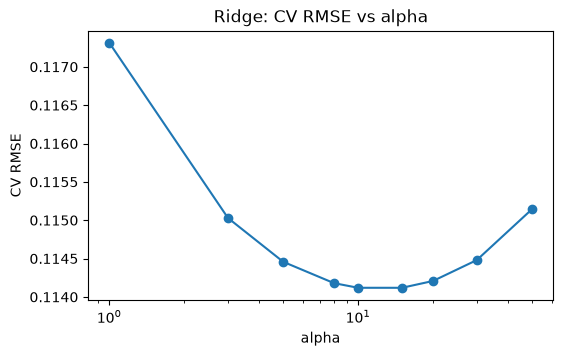

Ridge (tuned)                RMSE = 0.1141 ± 0.0078


In [11]:
ridge_grid = GridSearchCV(make_pipeline(RobustScaler(), Ridge()),
                          {'ridge__alpha': [1, 3, 5, 8, 10, 15, 20, 30, 50]},
                          cv=kf, scoring='neg_root_mean_squared_error')
ridge_grid.fit(X, y)
print('Best alpha:', ridge_grid.best_params_, ' CV RMSE:', round(-ridge_grid.best_score_, 4))

cvres = pd.DataFrame(ridge_grid.cv_results_)
plt.figure(figsize=(6, 3.5))
plt.plot(cvres['param_ridge__alpha'], -cvres['mean_test_score'], marker='o')
plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('CV RMSE'); plt.title('Ridge: CV RMSE vs alpha')
plt.savefig('ridge_tuning.png', dpi=120, bbox_inches='tight'); plt.show()
evaluate('Ridge (tuned)', ridge_grid.best_estimator_)

Small alpha overfits and large alpha underfits. The bottom of the curve is the best trade-off.

### Lasso: alpha

In [12]:
lasso_grid = GridSearchCV(make_pipeline(RobustScaler(), Lasso(max_iter=50000)),
                          {'lasso__alpha': [0.0001, 0.0002, 0.0003, 0.0005, 0.0008, 0.001, 0.002]},
                          cv=kf, scoring='neg_root_mean_squared_error')
lasso_grid.fit(X, y)
print('Best alpha:', lasso_grid.best_params_, ' CV RMSE:', round(-lasso_grid.best_score_, 4))
evaluate('Lasso (tuned)', lasso_grid.best_estimator_)

Best alpha: {'lasso__alpha': 0.0005}  CV RMSE: 0.1126
Lasso (tuned)                RMSE = 0.1126 ± 0.0067


### Gradient Boosting: tree depth and learning rate (small grid, because boosting is slow)

In [13]:
gb_grid = GridSearchCV(GradientBoostingRegressor(n_estimators=800, subsample=0.8, random_state=42),
                       {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.05]},
                       cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
gb_grid.fit(X, y)
print('Best params:', gb_grid.best_params_, ' CV RMSE:', round(-gb_grid.best_score_, 4))
evaluate('GradientBoosting (tuned)', gb_grid.best_estimator_)

Best params: {'learning_rate': 0.03, 'max_depth': 3}  CV RMSE: 0.1145
GradientBoosting (tuned)     RMSE = 0.1145 ± 0.0055


### Bonus: blend of Lasso + Gradient Boosting


In [14]:
from sklearn.ensemble import VotingRegressor
blend = VotingRegressor([('lasso', lasso_grid.best_estimator_), ('gb', gb_grid.best_estimator_)])
evaluate('Blend (Lasso + GB)', blend)

Blend (Lasso + GB)           RMSE = 0.1089 ± 0.0061


## C4 Comparison

In [15]:
comparison = pd.DataFrame({'Model': list(results),
                           'CV_RMSE_mean': [s.mean() for s in results.values()],
                           'CV_RMSE_std':  [s.std() for s in results.values()]}).round(4)
comparison = comparison.sort_values('CV_RMSE_mean').reset_index(drop=True)
comparison.to_csv('model_comparison.csv', index=False)
comparison

,Model,CV_RMSE_mean,CV_RMSE_std
0,Blend (Lasso + GB),0.1089,0.0061
1,Lasso,0.1126,0.0067
2,Lasso (tuned),0.1126,0.0067
3,Ridge (tuned),0.1141,0.0078
4,Ridge,0.1141,0.0078
5,GradientBoosting (tuned),0.1145,0.0055
6,GradientBoosting,0.1167,0.0058
7,RandomForest,0.1306,0.0078
8,Baseline (mean),0.3993,0.0168


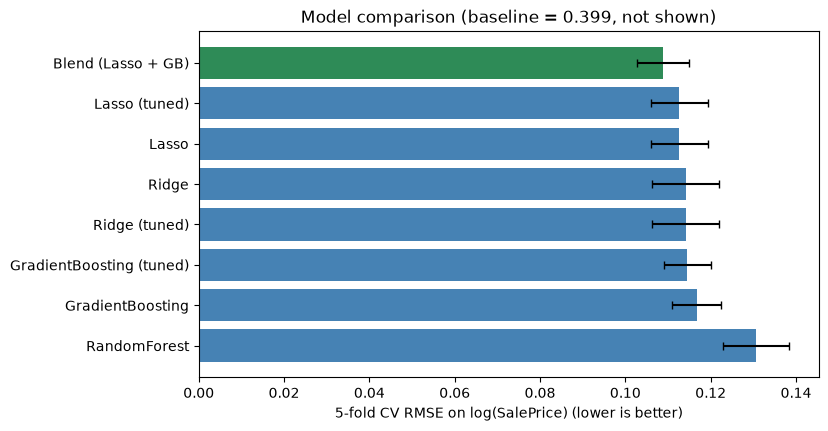

Winner: Blend (Lasso + GB)


In [16]:
plot = comparison[comparison['Model'] != 'Baseline (mean)'].sort_values('CV_RMSE_mean', ascending=False)
plt.figure(figsize=(8, 4.5))
plt.barh(plot['Model'], plot['CV_RMSE_mean'], xerr=plot['CV_RMSE_std'],
         color=['seagreen' if i == plot.index.min() else 'steelblue' for i in plot.index], capsize=3)
base = comparison.loc[comparison['Model'] == 'Baseline (mean)', 'CV_RMSE_mean'].item()
plt.xlabel('5-fold CV RMSE on log(SalePrice) (lower is better)')
plt.title(f'Model comparison (baseline = {base:.3f}, not shown)')
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight'); plt.show()

winner_name = comparison.loc[0, 'Model']
print('Winner:', winner_name)

In [17]:
models = {'Ridge (tuned)': ridge_grid.best_estimator_, 'Lasso (tuned)': lasso_grid.best_estimator_,
          'GradientBoosting (tuned)': gb_grid.best_estimator_, 'Blend (Lasso + GB)': blend}
winner = models.get(winner_name, blend)

**Choice:** the model with the lowest mean CV RMSE wins. All tuned models beat the baseline (≈0.40) by a wide margin. The linear models do very well here because the target was log-transformed and the skewed features were too, which made the relations close to linear. The blend is best because it combines linear and tree models, whose errors partly cancel. Random Forest is the weakest: its deep, averaged trees can't extrapolate to the most expensive houses.

## C5 Error analysis
We use `cross_val_predict`, so every house is predicted by a model that never saw it in training.

Out-of-fold RMSE: 0.1091


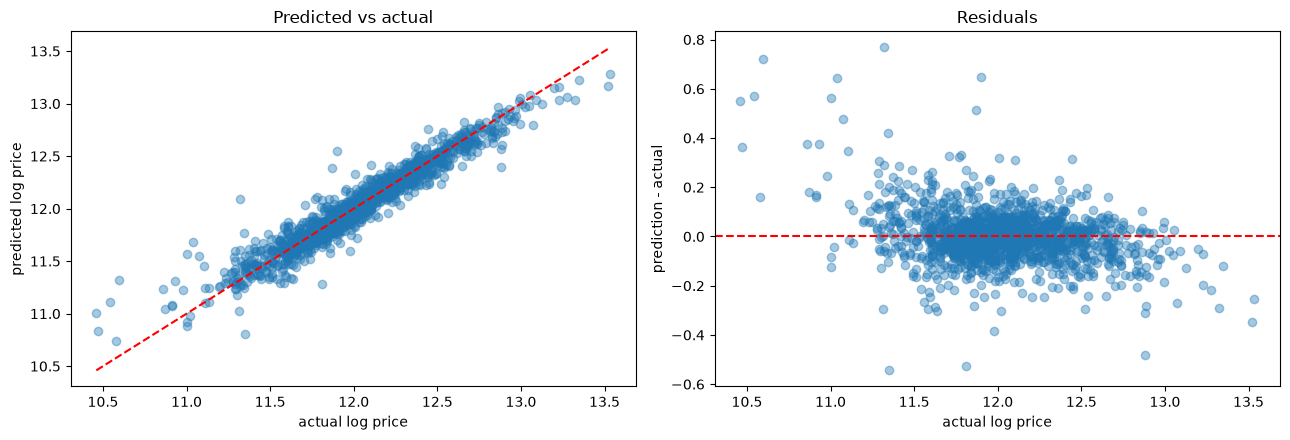

In [18]:
oof = cross_val_predict(winner, X, y, cv=kf)
raw = pd.read_csv('../data/raw/train.csv')
raw = raw.drop(raw[(raw['GrLivArea'] > 4000) & (raw['SalePrice'] < 300000)].index).reset_index(drop=True)
err = raw[['Id', 'Neighborhood', 'OverallQual', 'GrLivArea', 'YearBuilt', 'SaleCondition', 'SalePrice']].copy()
err['Predicted'] = np.expm1(oof).round(0)
err['log_error'] = oof - y                     
err['abs_log_error'] = err['log_error'].abs()
print('Out-of-fold RMSE:', round(np.sqrt((err['log_error']**2).mean()), 4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y, oof, alpha=0.4); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax[0].set_xlabel('actual log price'); ax[0].set_ylabel('predicted log price'); ax[0].set_title('Predicted vs actual')
ax[1].scatter(y, err['log_error'], alpha=0.4); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('actual log price'); ax[1].set_ylabel('prediction - actual'); ax[1].set_title('Residuals')
plt.tight_layout(); plt.savefig('error_analysis.png', dpi=120); plt.show()

### The 10 biggest mistakes

In [19]:
err.sort_values('abs_log_error', ascending=False).head(10)

,Id,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition,SalePrice,Predicted,log_error,abs_log_error
631,633,NWAmes,7,1411,1977,Family,82500,177798.0,0.767845,0.767845
30,31,IDOTRR,4,1317,1920,Normal,40000,82430.0,0.723063,0.723063
1322,1325,Somerst,8,1795,2006,Partial,147000,280798.0,0.647200,0.647200
462,463,Sawyer,5,864,1965,Normal,62383,118847.0,0.644538,0.644538
967,969,OldTown,3,968,1910,Abnorml,37900,66994.0,0.569633,0.569633
410,411,Edwards,5,1276,1958,Abnorml,60000,105348.0,0.562921,0.562921
495,496,IDOTRR,4,720,1920,Abnorml,34900,60471.0,0.549672,0.549672
88,89,IDOTRR,3,1526,1915,Abnorml,85000,49347.0,-0.543775,0.543775
969,971,NAmes,4,1192,1949,Abnorml,135000,79729.0,-0.526636,0.526636
587,589,ClearCr,5,1473,1968,Partial,143000,239367.0,0.515151,0.515151


### Errors by sale condition, price range and neighborhood

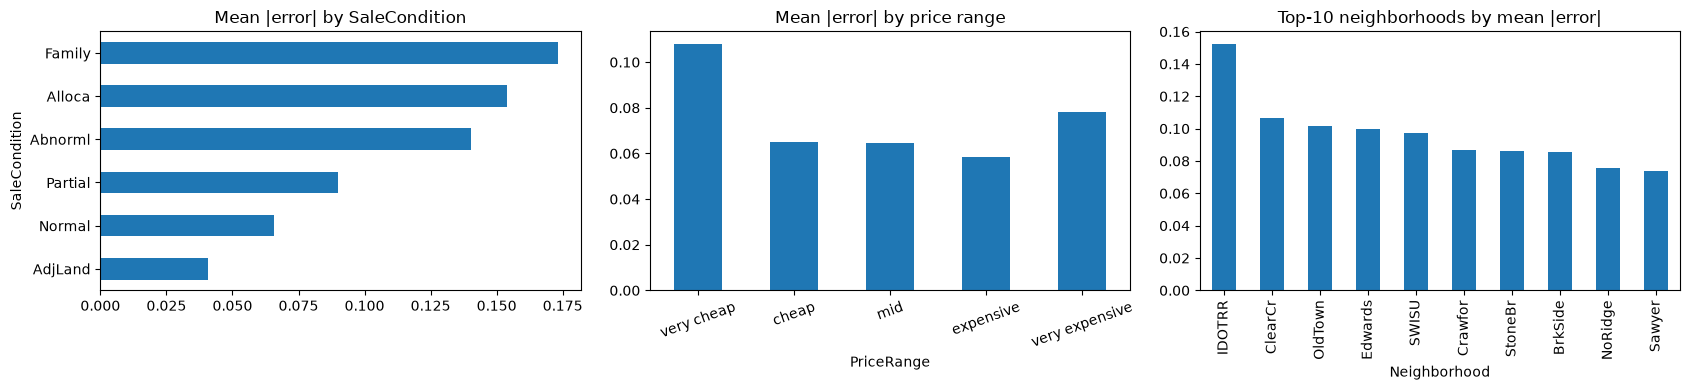

In [20]:
err['PriceRange'] = pd.qcut(err['SalePrice'], 5, labels=['very cheap', 'cheap', 'mid', 'expensive', 'very expensive'])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
err.groupby('SaleCondition')['abs_log_error'].mean().sort_values().plot.barh(ax=ax[0], title='Mean |error| by SaleCondition')
err.groupby('PriceRange', observed=True)['abs_log_error'].mean().plot.bar(ax=ax[1], title='Mean |error| by price range', rot=20)
err.groupby('Neighborhood')['abs_log_error'].mean().sort_values(ascending=False).head(10).plot.bar(ax=ax[2], title='Top-10 neighborhoods by mean |error|')
plt.tight_layout(); plt.savefig('error_by_group.png', dpi=120); plt.show()

**Findings:**
* The largest errors are mostly **overestimates of cheap houses**, often `Abnorml` (foreclosure / forced), `Family` or `Alloca` sales, where the price was below market value for reasons the features can't see. These sale types have about twice the mean error of `Normal` sales.
* Errors are highest in the **cheapest 20%** of houses and second-highest in the most expensive 20%. The residual plot shows the model pulls extreme prices toward the middle.
* Some neighborhoods (IDOTRR, OldTown, Edwards: older areas with many abnormal sales) have larger errors because house condition varies more there.
* Possible improvements: a flag for abnormal sales, or more features about house condition.

## C6 Submission

In [21]:
winner.fit(X, y)
pred = np.expm1(winner.predict(X_test))          
submission = pd.DataFrame({'Id': test_ids, 'SalePrice': pred})
fname = 'submission_' + winner_name.split(' ')[0].lower() + '.csv'
submission.to_csv(fname, index=False)

assert submission.shape == (1459, 2) and submission['SalePrice'].gt(0).all()
print('Saved', fname); submission.head()

Saved submission_blend.csv


,Id,SalePrice
0,1461,118639.743548
1,1462,159643.777122
2,1463,182388.343477
3,1464,195137.822844
4,1465,193230.372726


Upload this file at *kaggle.com/competitions/house-prices-advanced-regression-techniques → Submit Prediction*, then save a screenshot of the score as `submissions/kaggle_score.png`.

**Kaggle public score:** _fill in after submitting_